# EN3160 – Assignment 3: Neural Networks

**Name:** Anthony C.S.B.  
**Index No:** 230045X  
**GitHub:** https://github.com/BashithaAnthony/EN3160-Assignment-3-on-Neural-Networks


## Question 1 – Dense network with manual back-propagation

Listing 1 is a single-layer network trained with MSE loss, with the forward pass and gradients written by hand. I kept that style (no `autograd`, no `nn.Linear`) and made the three requested changes:

- **(a)** add a middle layer with 100 nodes and a sigmoid activation,
- **(b)** replace the MSE loss with cross-entropy,
- **(c)** train for 10 epochs and report the training and test accuracies.

I first run it with exactly the hyperparameters of Listing 1, and then with modified hyperparameters, and compare the two.


### Setup and data loading
The data pipeline is the same as in Listing 1 (CIFAR-10, normalised to $[-1, 1]$, batch size 50). Images are flattened to $3072$ inputs.


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

In [9]:
# 1. Data loading (same as Listing 1; num_workers=0 so it runs on Windows)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)

Din = 3 * 32 * 32   # flattened CIFAR-10 image
H = 100             # middle layer nodes
K = 10              # classes
epochs = 10

### (a), (b) Network and gradients

For a batch of $N$ flattened images $X$ with one-hot labels $Y$:

$$Z_1 = XW_1 + b_1,\quad H = \sigma(Z_1),\quad S = HW_2 + b_2,\quad P = \mathrm{softmax}(S)$$

$$L = -\frac{1}{N}\sum_{n}\sum_{k} Y_{nk}\log P_{nk} \;+\; \lambda\left(\lVert W_1\rVert^2 + \lVert W_2\rVert^2\right)$$

Back-propagating by hand:

$$\frac{\partial L}{\partial S} = \frac{P - Y}{N},\qquad \frac{\partial L}{\partial W_2} = H^\top\frac{\partial L}{\partial S} + 2\lambda W_2,\qquad \frac{\partial L}{\partial b_2} = \sum_n \frac{\partial L}{\partial S}$$

$$\frac{\partial L}{\partial Z_1} = \left(\frac{\partial L}{\partial S}W_2^\top\right)\odot H\odot(1-H),\qquad \frac{\partial L}{\partial W_1} = X^\top\frac{\partial L}{\partial Z_1} + 2\lambda W_1,\qquad \frac{\partial L}{\partial b_1} = \sum_n \frac{\partial L}{\partial Z_1}$$

In the code the softmax subtracts the row maximum before exponentiating to avoid overflow. $\lambda$ (`reg`) is 0, as in Listing 1.


### Implementation
The forward pass, loss, backward pass and accuracy function are kept as separate functions so that the training loop stays short.


In [10]:
def init_params(std):
    w1 = torch.randn(Din, H) * std
    b1 = torch.zeros(H)
    w2 = torch.randn(H, K) * std
    b2 = torch.zeros(K)
    return [w1, b1, w2, b2]


def forward(x, params):
    w1, b1, w2, b2 = params
    h1 = torch.sigmoid(x.mm(w1) + b1)      # middle layer (sigmoid)
    scores = h1.mm(w2) + b2                # output layer (logits)
    return h1, scores


def softmax(scores):
    shifted = scores - scores.max(dim=1, keepdim=True).values   # numerical stability
    exp_scores = torch.exp(shifted)
    return exp_scores / exp_scores.sum(dim=1, keepdim=True)


def loss_fn(probs, y_onehot, params, reg):
    ce = -torch.sum(y_onehot * torch.log(probs + 1e-8)) / probs.shape[0]
    w1, _, w2, _ = params
    return ce + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))


def backward(x, y_onehot, h1, probs, params, reg):
    w1, _, w2, _ = params
    N = x.shape[0]
    dscores = (probs - y_onehot) / N                  # softmax + cross-entropy
    dw2 = h1.t().mm(dscores) + 2 * reg * w2
    db2 = dscores.sum(dim=0)
    dz1 = dscores.mm(w2.t()) * h1 * (1.0 - h1)        # through the sigmoid
    dw1 = x.t().mm(dz1) + 2 * reg * w1
    db1 = dz1.sum(dim=0)
    return dw1, db1, dw2, db2


def accuracy(loader, params):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x, params)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

In [11]:
def run_experiment(std, lr, lr_decay=0.9, reg=0.0, epochs=10, seed=0):
    torch.manual_seed(seed)          # same init and batch order for every run
    lr0 = lr
    params = init_params(std)
    loss_history, epoch_loss = [], []

    for t in range(epochs):
        running_loss = 0.0
        for inputs, labels in trainloader:
            x = inputs.view(inputs.shape[0], -1)
            y = nn.functional.one_hot(labels, K).float()

            h1, scores = forward(x, params)
            probs = softmax(scores)
            loss = loss_fn(probs, y, params, reg)
            loss_history.append(loss.item())
            running_loss += loss.item()

            grads = backward(x, y, h1, probs, params, reg)
            for p, g in zip(params, grads):
                p -= lr * g                      # SGD update (in place)

        epoch_loss.append(running_loss / len(trainloader))
        print(f"Epoch {t + 1}/{epochs} | avg loss: {epoch_loss[-1]:.4f} | lr: {lr:.2e}")
        lr *= lr_decay

    return {"loss_history": loss_history, "epoch_loss": epoch_loss,
            "train_acc": accuracy(trainloader, params),
            "test_acc": accuracy(testloader, params),
            "std": std, "lr": lr0}

`run_experiment` trains the network with plain SGD and learning-rate decay (0.9 per epoch, as in Listing 1) and returns the loss history and final accuracies. The seed is fixed inside it, so both runs start from the same random numbers and see the same batch order.


### Gradient check
To make sure the hand-derived gradients are right, I compared them with PyTorch autograd on one batch (in float64, with a non-zero `reg`). Autograd is used only for this check, not for training.


In [12]:
# Compare the hand-written gradients with autograd on one batch (float64)
torch.manual_seed(0)
xb, yb = next(iter(trainloader))
x = xb.view(xb.shape[0], -1).double()
y = nn.functional.one_hot(yb, K).double()
reg_test = 1e-3                      # non-zero so the regularization gradient is tested too

params_auto = [p.double().requires_grad_() for p in init_params(1e-2)]
_, scores = forward(x, params_auto)
loss_fn(softmax(scores), y, params_auto, reg_test).backward()

with torch.no_grad():
    params_man = [p.detach() for p in params_auto]
    h1, scores = forward(x, params_man)
    grads_man = backward(x, y, h1, softmax(scores), params_man, reg_test)

for name, p, g in zip(["w1", "b1", "w2", "b2"], params_auto, grads_man):
    rel_err = ((p.grad - g).abs().max() / (p.grad.abs().max() + 1e-12)).item()
    print(f"{name}: max relative error = {rel_err:.2e}")

w1: max relative error = 9.74e-08
b1: max relative error = 1.02e-07
w2: max relative error = 1.02e-07
b2: max relative error = 1.02e-07


All four relative errors are about $10^{-7}$ (largest $1.02\times10^{-7}$). This small residual comes from the `1e-8` added inside the log, so the back-propagation is correct.

In [33]:
def plot_run(res, title, window=100, ylim=None):
    hist = np.array(res["loss_history"])
    smooth = np.convolve(hist, np.ones(window) / window, mode="valid")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist, alpha=0.3, label="per iteration")
    ax[0].plot(np.arange(window - 1, len(hist)), smooth, label=f"moving average ({window})")
    ax[0].set_title(f"{title}: loss history")
    ax[0].set_xlabel("Iteration")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].plot(range(1, len(res["epoch_loss"]) + 1), res["epoch_loss"], marker="o")
    ax[1].set_title(f"{title}: average loss per epoch")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    if ylim:
        ax[0].set_ylim(*ylim)
        ax[1].set_ylim(*ylim)
    plt.tight_layout()
    plt.show()

### (c) Run 1 – settings exactly as in Listing 1
Only changes (a) and (b) are applied. Hyperparameters are unchanged: `std = 1e-5`, `lr = 2e-6`, `lr_decay = 0.9`, `reg = 0`, batch size 50, 10 epochs.


Epoch 1/10 | avg loss: 2.3026 | lr: 2.00e-06
Epoch 2/10 | avg loss: 2.3026 | lr: 1.80e-06
Epoch 3/10 | avg loss: 2.3026 | lr: 1.62e-06
Epoch 4/10 | avg loss: 2.3026 | lr: 1.46e-06
Epoch 5/10 | avg loss: 2.3026 | lr: 1.31e-06
Epoch 6/10 | avg loss: 2.3026 | lr: 1.18e-06
Epoch 7/10 | avg loss: 2.3026 | lr: 1.06e-06
Epoch 8/10 | avg loss: 2.3026 | lr: 9.57e-07
Epoch 9/10 | avg loss: 2.3026 | lr: 8.61e-07
Epoch 10/10 | avg loss: 2.3026 | lr: 7.75e-07

Training accuracy: 10.00%
Test accuracy:     10.00%


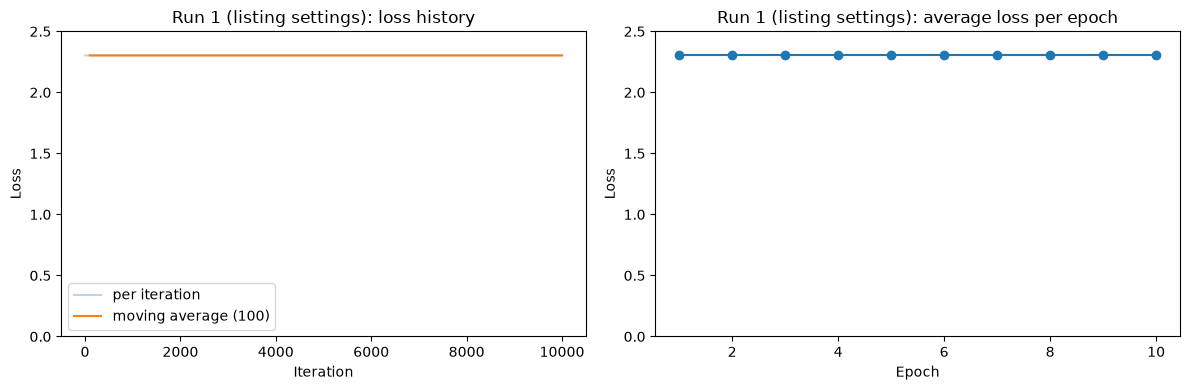

In [34]:
res1 = run_experiment(std=1e-5, lr=2e-6, lr_decay=0.9, reg=0.0, epochs=10)
print(f"\nTraining accuracy: {res1['train_acc']:.2f}%")
print(f"Test accuracy:     {res1['test_acc']:.2f}%")
plot_run(res1, "Run 1 (listing settings)", ylim=(0, 2.5))

**Observation.** Run 1 does not learn at all. The average loss is 2.3026 $\approx \ln 10$ in all 10 epochs (the loss of a uniform guess over 10 classes), and both training and test accuracy are exactly 10.00% (chance level, consistent with predicting one class for every image). Two reasons:

- With weights of order $10^{-5}$, the pre-activations $Z_1$ are only of order $10^{-4}$ (my estimate for 3072 inputs in $[-1, 1]$), so every hidden node outputs about $\sigma(0) = 0.5$ whatever the image. The hidden layer passes almost no information about the input.
- The gradient reaching $W_1$ is multiplied by $W_2$, which is also of order $10^{-5}$, and the learning rate is only $2\times10^{-6}$ (decaying to $7.75\times10^{-7}$ by epoch 10), so the weights hardly move.

These values were suitable for the original single-layer MSE network, but not for this deeper network with cross-entropy.

### Run 2 – modified hyperparameters
I changed only the following two (everything else is the same as in Run 1):

- `std`: $10^{-5} \rightarrow 10^{-2}$ (×1000), so the pre-activations $Z_1$ have a useful spread and the sigmoid outputs differ between images.
- `lr`: $2\times10^{-6} \rightarrow 0.1$ (×50,000). The cross-entropy gradient $(P-Y)/N$ is bounded and averaged over the batch, so a much larger step can be used.

Epoch 1/10 | avg loss: 1.9000 | lr: 1.00e-01
Epoch 2/10 | avg loss: 1.7177 | lr: 9.00e-02
Epoch 3/10 | avg loss: 1.6512 | lr: 8.10e-02
Epoch 4/10 | avg loss: 1.6038 | lr: 7.29e-02
Epoch 5/10 | avg loss: 1.5647 | lr: 6.56e-02
Epoch 6/10 | avg loss: 1.5299 | lr: 5.90e-02
Epoch 7/10 | avg loss: 1.5001 | lr: 5.31e-02
Epoch 8/10 | avg loss: 1.4729 | lr: 4.78e-02
Epoch 9/10 | avg loss: 1.4487 | lr: 4.30e-02
Epoch 10/10 | avg loss: 1.4273 | lr: 3.87e-02

Training accuracy: 51.80%
Test accuracy:     47.53%


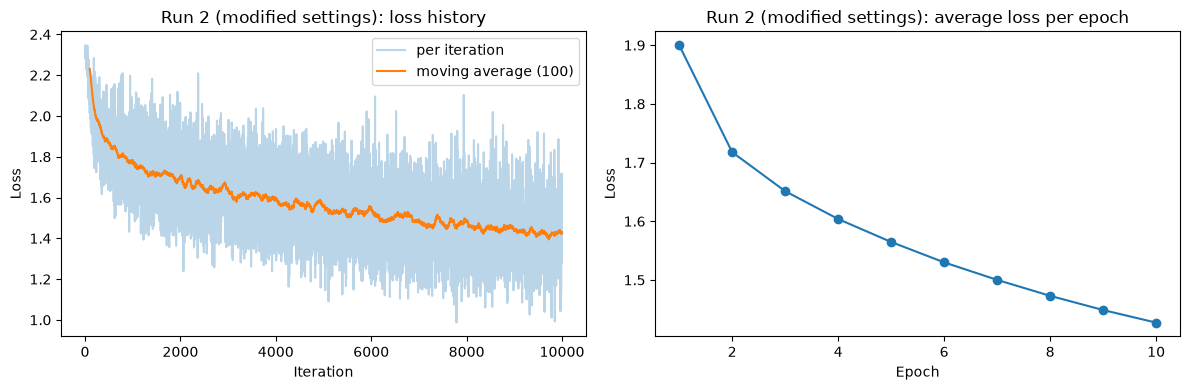

In [15]:
res2 = run_experiment(std=1e-2, lr=0.1, lr_decay=0.9, reg=0.0, epochs=10)
print(f"\nTraining accuracy: {res2['train_acc']:.2f}%")
print(f"Test accuracy:     {res2['test_acc']:.2f}%")
plot_run(res2, "Run 2 (modified settings)")

**Observation.** The average loss falls from 1.9000 in epoch 1 to 1.4273 in epoch 10 (a 25% reduction), and the accuracies are 51.80% (train) and 47.53% (test), about five times the 10% chance level. The improvement per epoch shrinks from 0.18 (epoch 1→2) to 0.02 (epoch 9→10) as the learning rate decays from 0.1 to 0.039, but the loss is still decreasing, so the network has not fully converged in 10 epochs. The per-iteration loss is noisy (roughly 1.0 to 1.9 in the last epochs) because each step uses only 50 images, so the moving average is used to see the trend.

### Results and discussion


Run                              std       lr  Final loss  Train %  Test %
Run 1 (listing settings)       1e-05    2e-06      2.3026    10.00   10.00
Run 2 (modified settings)       0.01      0.1      1.4273    51.80   47.53


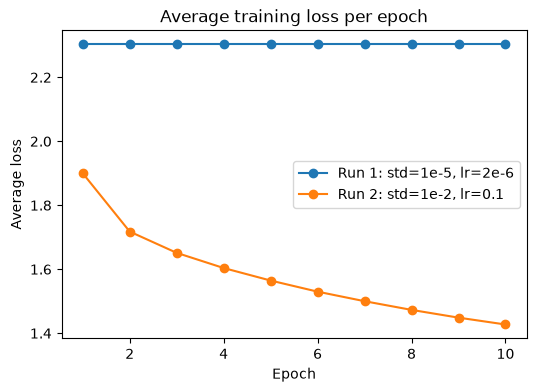

In [40]:
print(f"{'Run':<28}{'std':>8}{'lr':>9}{'Final loss':>12}{'Train %':>9}{'Test %':>8}")
for name, r in [("Run 1 (listing settings)", res1), ("Run 2 (modified settings)", res2)]:
    print(f"{name:<28}{r['std']:>8g}{r['lr']:>9g}{r['epoch_loss'][-1]:>12.4f}{r['train_acc']:>9.2f}{r['test_acc']:>8.2f}")
    
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), res1["epoch_loss"], marker="o", label="Run 1: std=1e-5, lr=2e-6")
plt.plot(range(1, 11), res2["epoch_loss"], marker="o", label="Run 2: std=1e-2, lr=0.1")
plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("Average training loss per epoch")
plt.legend()
plt.show()

- **Answer to (c):** Run 1 (Listing 1 settings): training accuracy 10.00%, test accuracy 10.00%. Run 2 (modified settings): training accuracy 51.80%, test accuracy 47.53%. Run 2 is the working model.
- Run 1 already has the new architecture and loss, so its failure comes from the initialisation and learning rate that were chosen for the old single-layer MSE network, not from the architecture. I changed `std` and `lr` together, so I cannot say how much each one contributes.
- In Run 2 the training accuracy is 4.27 points higher than the test accuracy (51.80% vs 47.53%), a mild over-fitting.
- A test accuracy of 47.53% is far below what convolutional networks reach on CIFAR-10 (small CNNs typically exceed 70%). Flattening the image throws away the spatial structure, and sigmoid units can saturate and give small gradients. Convolutional networks, used in Question 2, address the first problem.

## Question 2 – LeNet-5 vs a modern small CNN on MNIST

I trained two CNNs on MNIST (images normalised to $[-1, 1]$) under identical conditions: cross-entropy loss, Adam with learning rate $10^{-3}$, batch size 64, 10 epochs and the same random seed. Training and test loss/accuracy are logged after every epoch and a confusion matrix is computed on the test set for each model.


In [17]:
import torch.optim as optim
import seaborn as sns
from sklearn.metrics import confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform_mnist = transforms.Compose([transforms.ToTensor(),
                                      transforms.Normalize((0.5,), (0.5,))])

mnist_train = torchvision.datasets.MNIST(root='./data', train=True,
                                         download=True, transform=transform_mnist)
mnist_trainloader = torch.utils.data.DataLoader(mnist_train, batch_size=64, shuffle=True)

mnist_test = torchvision.datasets.MNIST(root='./data', train=False,
                                        download=True, transform=transform_mnist)
mnist_testloader = torch.utils.data.DataLoader(mnist_test, batch_size=64, shuffle=False)

digit_classes = [str(i) for i in range(10)]

### (a), (b) Models

**LeNet-5.** Conv(1→6, 5×5, padding 2) → AvgPool → Conv(6→16, 5×5) → AvgPool → FC 400→120→84→10. The padding of 2 makes the $28\times28$ MNIST image behave like the $32\times32$ input of the original LeNet-5. I used ReLU instead of the original tanh.

**Modern small CNN.** Three blocks of Conv(3×3) → BatchNorm → ReLU → MaxPool with 16, 32 and 64 channels, followed by Dropout(0.5) → FC 576→128 → BatchNorm → ReLU → Dropout(0.5) → FC 128→10. Batch normalisation stabilises and speeds up training, and dropout acts as a regulariser.


In [18]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)   # 1x28x28 -> 6x28x28
        self.pool1 = nn.AvgPool2d(2, 2)                          # -> 6x14x14
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)             # -> 16x10x10
        self.pool2 = nn.AvgPool2d(2, 2)                          # -> 16x5x5
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool1(self.relu(self.conv1(x)))
        x = self.pool2(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)


class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2, 2),   # 16x14x14
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2, 2),  # 32x7x7
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2, 2),  # 64x3x3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(64 * 3 * 3, 128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

### (c) Training, logging and plots
After every epoch both the training and test sets are evaluated with the model in evaluation mode. This way dropout does not distort the training numbers and the two models can be compared fairly. The confusion matrix is from the final model (after epoch 10).


In [19]:
def evaluate(model, loader, criterion):
    model.eval()                                   # dropout off, batch-norm uses running stats
    running_loss, correct, total = 0.0, 0, 0
    all_labels, all_preds = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            running_loss += criterion(outputs, labels).item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_labels.extend(labels.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())
    return running_loss / total, 100.0 * correct / total, all_labels, all_preds


def train_model(model_cls, name, epochs=10, lr=1e-3, seed=0):
    torch.manual_seed(seed)                        # same conditions for both models
    model = model_cls().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    print(f"--- Training {name} ---")
    for epoch in range(epochs):
        model.train()
        for inputs, labels in mnist_trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()

        # both curves are measured in eval mode after each epoch
        tr_loss, tr_acc, _, _ = evaluate(model, mnist_trainloader, criterion)
        te_loss, te_acc, labels_all, preds_all = evaluate(model, mnist_testloader, criterion)
        for k, v in zip(history, (tr_loss, te_loss, tr_acc, te_acc)):
            history[k].append(v)
        print(f"Epoch {epoch + 1}/{epochs} | Train loss {tr_loss:.4f}, acc {tr_acc:.2f}% | "
              f"Test loss {te_loss:.4f}, acc {te_acc:.2f}%")

    n_params = sum(p.numel() for p in model.parameters())
    return {"history": history, "labels": labels_all, "preds": preds_all, "params": n_params}

In [20]:
def plot_history(history, name):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, history["train_loss"], marker="o", label="Train")
    ax[0].plot(ep, history["test_loss"], marker="s", label="Test")
    ax[0].set_title(f"{name}: loss per epoch")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[1].plot(ep, history["train_acc"], marker="o", label="Train")
    ax[1].plot(ep, history["test_acc"], marker="s", label="Test")
    ax[1].set_title(f"{name}: accuracy per epoch")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy (%)")
    for a in ax:
        a.grid(True)
        a.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(labels, preds, name):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=digit_classes, yticklabels=digit_classes)
    plt.title(f"{name}: confusion matrix (test set)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

#### LeNet-5 results


--- Training LeNet-5 ---
Epoch 1/10 | Train loss 0.1110, acc 96.54% | Test loss 0.1021, acc 96.74%
Epoch 2/10 | Train loss 0.0723, acc 97.71% | Test loss 0.0632, acc 97.99%
Epoch 3/10 | Train loss 0.0488, acc 98.43% | Test loss 0.0485, acc 98.36%
Epoch 4/10 | Train loss 0.0473, acc 98.54% | Test loss 0.0488, acc 98.38%
Epoch 5/10 | Train loss 0.0389, acc 98.84% | Test loss 0.0469, acc 98.50%
Epoch 6/10 | Train loss 0.0275, acc 99.16% | Test loss 0.0386, acc 98.80%
Epoch 7/10 | Train loss 0.0260, acc 99.17% | Test loss 0.0409, acc 98.64%
Epoch 8/10 | Train loss 0.0190, acc 99.40% | Test loss 0.0312, acc 99.07%
Epoch 9/10 | Train loss 0.0233, acc 99.24% | Test loss 0.0464, acc 98.46%
Epoch 10/10 | Train loss 0.0224, acc 99.26% | Test loss 0.0383, acc 98.86%


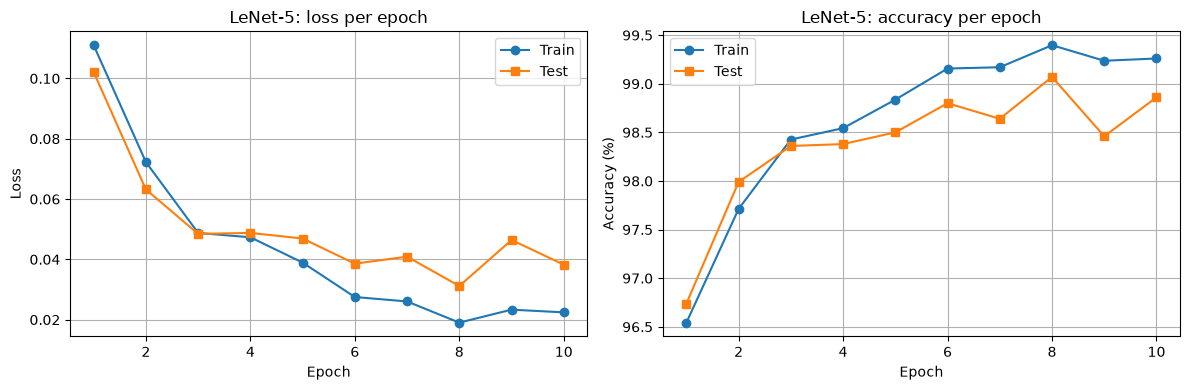

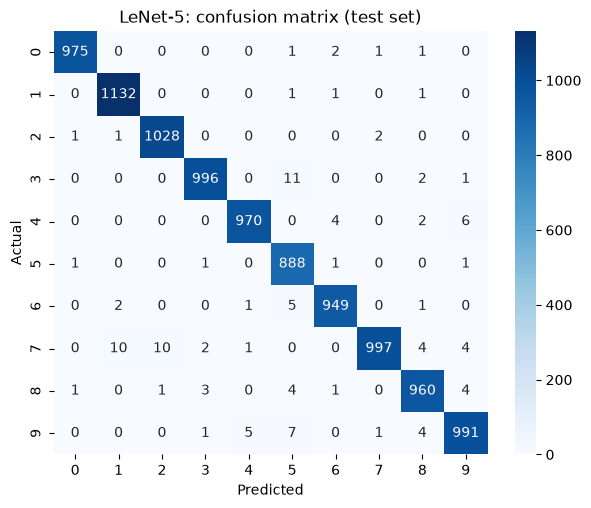

In [21]:
res_lenet = train_model(LeNet5, "LeNet-5")
plot_history(res_lenet["history"], "LeNet-5")
plot_confusion_matrix(res_lenet["labels"], res_lenet["preds"], "LeNet-5")

#### Modern small CNN results


--- Training Modern small CNN ---
Epoch 1/10 | Train loss 0.0451, acc 98.66% | Test loss 0.0417, acc 98.69%
Epoch 2/10 | Train loss 0.0297, acc 99.12% | Test loss 0.0315, acc 98.92%
Epoch 3/10 | Train loss 0.0239, acc 99.26% | Test loss 0.0274, acc 99.05%
Epoch 4/10 | Train loss 0.0216, acc 99.31% | Test loss 0.0256, acc 99.13%
Epoch 5/10 | Train loss 0.0179, acc 99.45% | Test loss 0.0212, acc 99.34%
Epoch 6/10 | Train loss 0.0160, acc 99.51% | Test loss 0.0210, acc 99.26%
Epoch 7/10 | Train loss 0.0158, acc 99.50% | Test loss 0.0230, acc 99.25%
Epoch 8/10 | Train loss 0.0134, acc 99.59% | Test loss 0.0222, acc 99.25%
Epoch 9/10 | Train loss 0.0131, acc 99.59% | Test loss 0.0199, acc 99.38%
Epoch 10/10 | Train loss 0.0115, acc 99.65% | Test loss 0.0203, acc 99.31%


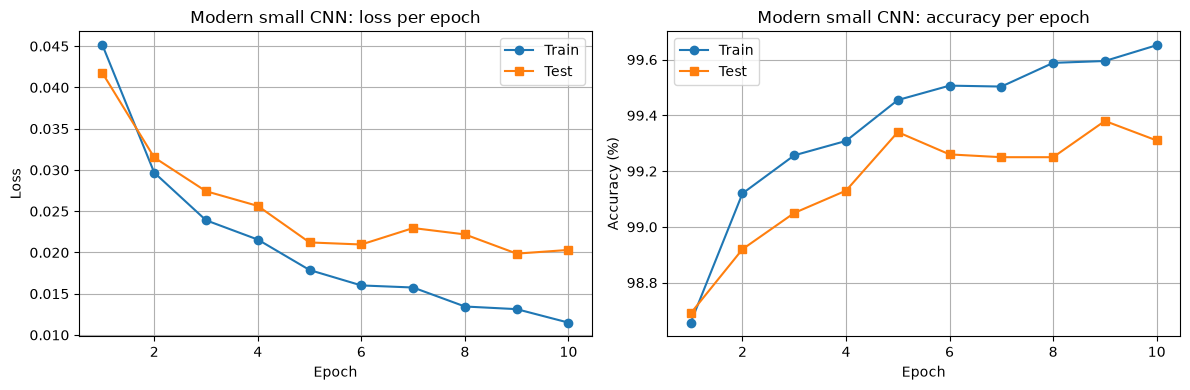

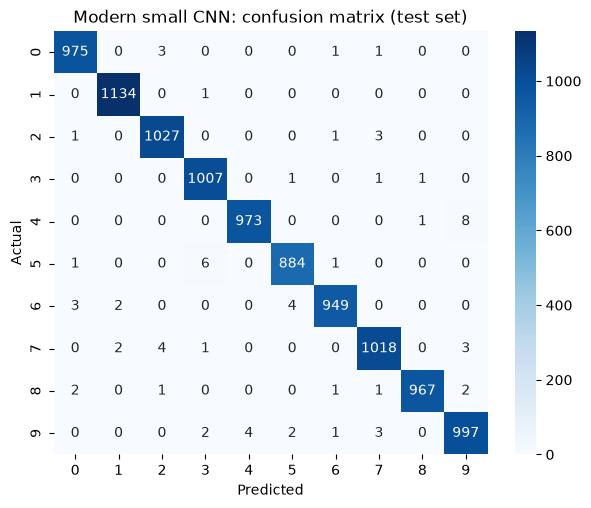

In [22]:
res_modern = train_model(ModernCNN, "Modern small CNN")
plot_history(res_modern["history"], "Modern small CNN")
plot_confusion_matrix(res_modern["labels"], res_modern["preds"], "Modern small CNN")

### Comparison


In [39]:
print(f"{'Model':<20}{'Params':>9}{'Train acc':>11}{'Test acc':>10}{'Train loss':>12}{'Test loss':>11}")
for name, r in [("LeNet-5", res_lenet), ("Modern small CNN", res_modern)]:
    h = r["history"]
    print(f"{name:<20}{r['params']:>9,}{h['train_acc'][-1]:>11.2f}{h['test_acc'][-1]:>10.2f}{h['train_loss'][-1]:>12.4f}{h['test_loss'][-1]:>11.4f}")

Model                  Params  Train acc  Test acc  Train loss  Test loss
LeNet-5                61,706      99.26     98.86      0.0224     0.0383
Modern small CNN       98,922      99.65     99.31      0.0115     0.0203


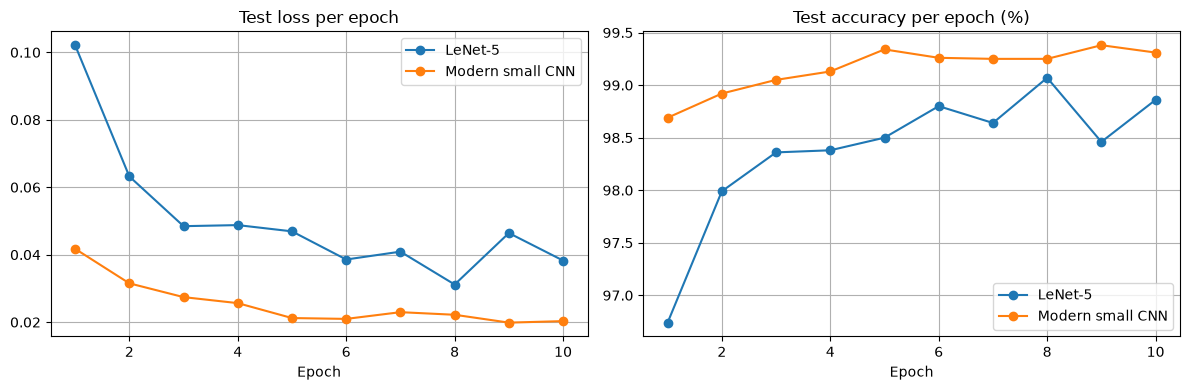

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for res, name in [(res_lenet, "LeNet-5"), (res_modern, "Modern small CNN")]:
    ep = range(1, 11)
    ax[0].plot(ep, res["history"]["test_loss"], marker="o", label=name)
    ax[1].plot(ep, res["history"]["test_acc"], marker="o", label=name)
ax[0].set_title("Test loss per epoch")
ax[1].set_title("Test accuracy per epoch (%)")
for a in ax:
    a.set_xlabel("Epoch")
    a.grid(True)
    a.legend()
plt.tight_layout()
plt.show()

- **Answer to (a), (b):** after 10 epochs LeNet-5 reaches 99.26% training and 98.86% test accuracy, and the modern CNN reaches 99.65% and 99.31%. The modern CNN is 0.45 points better on the test set, i.e. 45 more of the 10,000 images are correct (69 errors vs 114, 39% fewer).
- **Training behaviour:** after epoch 1 the modern CNN is already at 98.69% test accuracy against 96.74% for LeNet-5, which shows the faster convergence given by batch normalisation. In epochs 6–10 the LeNet-5 test accuracy varies between 98.46% and 99.07% (0.61 points) and its test loss jumps from 0.0312 (epoch 8) to 0.0464 (epoch 9). The modern CNN stays within 99.25–99.38% (0.13 points) with test loss between 0.0199 and 0.0230.
- **Over-fitting:** the train–test accuracy gap is 0.40 points (loss gap 0.0159) for LeNet-5 and 0.34 points (loss gap 0.0088) for the modern CNN. Both generalise well, and the loss gap of the modern CNN is about half, but MNIST is easy so over-fitting is mild in both.
- **Model size:** the modern CNN has 98,922 parameters against 61,706 for LeNet-5 (1.6×), so part of its gain may come from the larger size. I did not test this separately.
- **Confusion matrices:** both are strongly diagonal. LeNet-5 makes 114 errors; the largest confusions are 3→5 (11 images), 7→1 (10) and 7→2 (10), and digit 7 alone accounts for 31 errors (27% of the total). In the modern CNN the digit-7 errors drop to 10 and the largest confusions are 4→9 (8) and 5→3 (6). It is not better for every digit: the errors for digit 5 rise from 4 to 8.
- **Reliability:** these are single runs (one seed). The sampling error of a test accuracy near 99% on 10,000 images is about 0.1 points, so the 0.45-point gap is larger than that, but seed-to-seed variation was not measured. I therefore call the modern CNN slightly better, not clearly superior.

## Question 3 – Transfer learning with ResNet18 on the hymenoptera dataset

Following the PyTorch transfer-learning tutorial, I took a ResNet18 pre-trained on ImageNet1K and used it to classify **ants vs bees** (hymenoptera dataset). The final fully connected layer (512 → 1000) is replaced by a new one with 2 outputs, and the network is used in two ways:

- **(a) Fine-tuning:** all layers start from the pre-trained weights and are all trained.
- **(b) Feature extractor:** the whole network is frozen and only the new final layer is trained.


### Setup
- **Data:** 244 training and 153 validation images. Training images use `RandomResizedCrop(224)` and a random horizontal flip; validation images use `Resize(256)` and `CenterCrop(224)`. Both are normalised with the ImageNet mean and std, batch size 4.
- **Training (same for both):** cross-entropy, SGD with learning rate 0.001 and momentum 0.9, learning rate multiplied by 0.1 every 7 epochs, 10 epochs, same seed.
- **Pre-trained weights:** loaded from a local `resnet18` folder next to the notebook. If they are not there, they are downloaded once and saved in that folder.
- The validation set is the only held-out set in this dataset, so it is used as the "test" data here.


In [25]:
import os
import time
import copy
import torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

imagenet_norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
data_transforms = {
    "train": transforms.Compose([transforms.RandomResizedCrop(224),
                                 transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), imagenet_norm]),
    "val": transforms.Compose([transforms.Resize(256),
                               transforms.CenterCrop(224),
                               transforms.ToTensor(), imagenet_norm]),
}

data_dir = os.path.join("data", "hymenoptera_data")
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                  for x in ["train", "val"]}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=(x == "train"), num_workers=0)
               for x in ["train", "val"]}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print(dataset_sizes, class_names)

{'train': 244, 'val': 153} ['ants', 'bees']


In [26]:
MODEL_NAME = "resnet18"
MODEL_DIR = os.path.join(BASE_DIR, MODEL_NAME)          # folder named after the model
WEIGHTS_PATH = os.path.join(MODEL_DIR, f"{MODEL_NAME}_imagenet1k_v1.pth")


def load_pretrained_resnet18():
    """Load ImageNet1K ResNet18 from the local folder; download and save it there if missing."""
    if os.path.exists(WEIGHTS_PATH):
        print(f"Loading pretrained weights from {WEIGHTS_PATH}")
        model = models.resnet18(weights=None)
        model.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
    else:
        print("Pretrained weights not found locally, downloading...")
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        os.makedirs(MODEL_DIR, exist_ok=True)
        torch.save(model.state_dict(), WEIGHTS_PATH)
        print(f"Saved weights to {WEIGHTS_PATH}")
    return model

### Implementation
`build_finetune` and `build_feature_extractor` differ only in which parameters are trainable: for the feature extractor `requires_grad` is set to `False` for the backbone and the optimiser receives only the new layer's parameters. The same `train_resnet` loop is used for both.


In [27]:
def fmt_time(seconds):
    m, s = divmod(round(seconds), 60)
    return f"{m}m {s}s"


def build_finetune():
    model = load_pretrained_resnet18()
    model.fc = nn.Linear(model.fc.in_features, len(class_names))   # 2 classes
    model = model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)   # all layers trained
    return model, optimizer


def build_feature_extractor():
    model = load_pretrained_resnet18()
    for p in model.parameters():
        p.requires_grad = False                                    # freeze the backbone
    model.fc = nn.Linear(model.fc.in_features, len(class_names))   # new layer is trainable
    model = model.to(device)
    optimizer = optim.SGD(model.fc.parameters(), lr=0.001, momentum=0.9)   # only fc trained
    return model, optimizer


def train_resnet(model, optimizer, scheduler, num_epochs=10):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
    since = time.time()

    for epoch in range(num_epochs):
        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()
            running_loss, running_corrects = 0.0, 0

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += (outputs.argmax(dim=1) == labels).sum().item()

            if phase == "train":
                scheduler.step()
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = 100.0 * running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "val" and epoch_acc > best_acc:
                best_acc, best_wts = epoch_acc, copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch + 1}/{num_epochs} | "
              f"train loss {history['train_loss'][-1]:.4f}, acc {history['train_acc'][-1]:.2f}% | "
              f"val loss {history['val_loss'][-1]:.4f}, acc {history['val_acc'][-1]:.2f}%")

    elapsed = time.time() - since
    model.load_state_dict(best_wts)          # keep the best-validation weights
    return model, history, best_acc, elapsed


def run_transfer(build_fn, name, num_epochs=10, seed=0):
    torch.manual_seed(seed)
    model, optimizer = build_fn()
    scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"--- {name} | trainable parameters: {trainable:,} ---")
    _, history, best_acc, elapsed = train_resnet(model, optimizer, scheduler, num_epochs)
    print(f"Training time: {fmt_time(elapsed)} | best val acc: {best_acc:.2f}%")
    return {"history": history, "best_val_acc": best_acc, "time": elapsed, "trainable": trainable}


def plot_transfer(history, name):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, history["train_loss"], marker="o", label="Train")
    ax[0].plot(ep, history["val_loss"], marker="s", label="Validation")
    ax[0].set_title(f"{name}: loss per epoch")
    ax[0].set_ylabel("Loss")
    ax[1].plot(ep, history["train_acc"], marker="o", label="Train")
    ax[1].plot(ep, history["val_acc"], marker="s", label="Validation")
    ax[1].set_title(f"{name}: accuracy per epoch")
    ax[1].set_ylabel("Accuracy (%)")
    for a in ax:
        a.set_xlabel("Epoch")
        a.grid(True)
        a.legend()
    plt.tight_layout()
    plt.show()

### (a) Fine-tuning


Loading pretrained weights from c:\Users\user\OneDrive\Desktop\5th Sem\Image proc. & Machine Vision\Assignment_3\EN3160-Assignment-3-on-Neural-Networks\resnet18\resnet18_imagenet1k_v1.pth
--- Fine-tuning | trainable parameters: 11,177,538 ---
Epoch 1/10 | train loss 0.5837, acc 68.85% | val loss 0.2394, acc 92.81%
Epoch 2/10 | train loss 0.5221, acc 76.64% | val loss 0.2254, acc 90.85%
Epoch 3/10 | train loss 0.6868, acc 70.90% | val loss 0.2913, acc 90.20%
Epoch 4/10 | train loss 0.4318, acc 82.38% | val loss 0.3622, acc 86.27%
Epoch 5/10 | train loss 0.4494, acc 80.74% | val loss 0.2596, acc 88.24%
Epoch 6/10 | train loss 0.2792, acc 89.34% | val loss 0.1674, acc 93.46%
Epoch 7/10 | train loss 0.4376, acc 81.15% | val loss 0.2782, acc 88.24%
Epoch 8/10 | train loss 0.4046, acc 84.02% | val loss 0.1920, acc 90.85%
Epoch 9/10 | train loss 0.4221, acc 79.92% | val loss 0.1952, acc 91.50%
Epoch 10/10 | train loss 0.3233, acc 86.07% | val loss 0.1862, acc 92.16%
Training time: 4m 20s | be

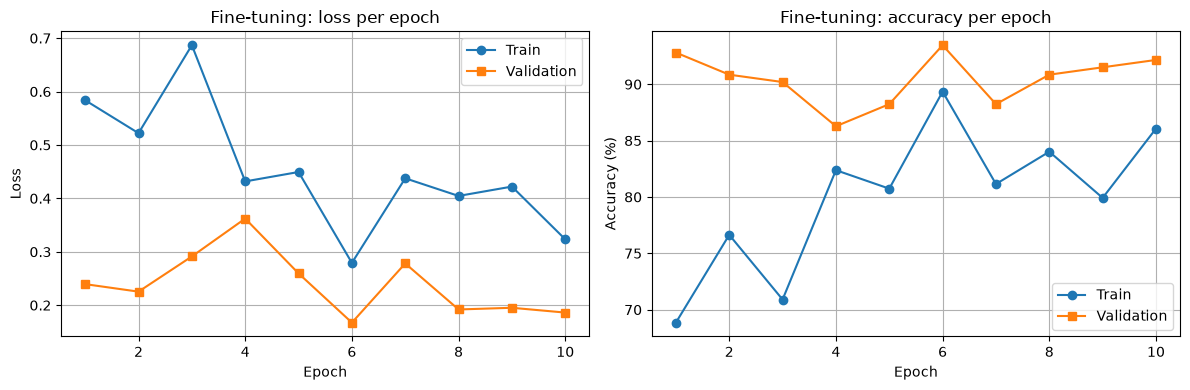

In [28]:
res_ft = run_transfer(build_finetune, "Fine-tuning")
plot_transfer(res_ft["history"], "Fine-tuning")

### (b) Feature extractor


Loading pretrained weights from c:\Users\user\OneDrive\Desktop\5th Sem\Image proc. & Machine Vision\Assignment_3\EN3160-Assignment-3-on-Neural-Networks\resnet18\resnet18_imagenet1k_v1.pth
--- Feature extractor | trainable parameters: 1,026 ---
Epoch 1/10 | train loss 0.6505, acc 63.93% | val loss 0.2278, acc 90.85%
Epoch 2/10 | train loss 0.5138, acc 75.82% | val loss 0.1872, acc 95.42%
Epoch 3/10 | train loss 0.6807, acc 70.08% | val loss 0.1718, acc 94.77%
Epoch 4/10 | train loss 0.4656, acc 81.97% | val loss 0.1525, acc 96.08%
Epoch 5/10 | train loss 0.4344, acc 79.92% | val loss 0.2104, acc 92.81%
Epoch 6/10 | train loss 0.3057, acc 85.25% | val loss 0.1705, acc 95.42%
Epoch 7/10 | train loss 0.3711, acc 82.38% | val loss 0.1670, acc 94.77%
Epoch 8/10 | train loss 0.3751, acc 84.43% | val loss 0.1589, acc 95.42%
Epoch 9/10 | train loss 0.4059, acc 80.33% | val loss 0.1723, acc 94.77%
Epoch 10/10 | train loss 0.3722, acc 85.25% | val loss 0.1539, acc 95.42%
Training time: 2m 38s | b

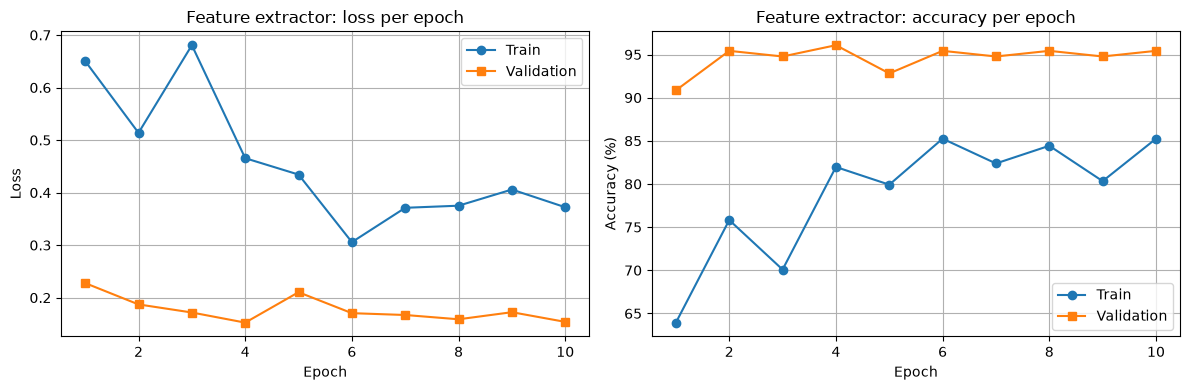

In [29]:
res_fe = run_transfer(build_feature_extractor, "Feature extractor")
plot_transfer(res_fe["history"], "Feature extractor")

### Results and discussion


Method                    Trainable params     Time  Final train  Final val  Best val
(a) Fine-tuning                 11,177,538   4m 20s        86.07      92.16     93.46
(b) Feature extractor                1,026   2m 38s        85.25      95.42     96.08


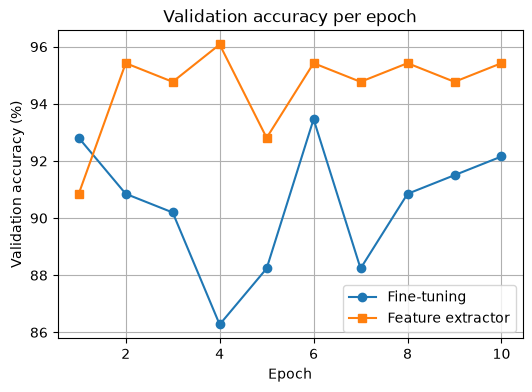

In [41]:
print(f"{'Method':<24}{'Trainable params':>18}{'Time':>9}{'Final train':>13}{'Final val':>11}{'Best val':>10}")
for name, r in [("(a) Fine-tuning", res_ft), ("(b) Feature extractor", res_fe)]:
    h = r["history"]
    print(f"{name:<24}{r['trainable']:>18,}{fmt_time(r['time']):>9}{h['train_acc'][-1]:>13.2f}{h['val_acc'][-1]:>11.2f}{r['best_val_acc']:>10.2f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), res_ft["history"]["val_acc"], marker="o", label="Fine-tuning")
plt.plot(range(1, 11), res_fe["history"]["val_acc"], marker="s", label="Feature extractor")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("Validation accuracy per epoch")
plt.grid(True)
plt.legend()
plt.show()

- **Answer to (a), (b):** fine-tuning reaches 92.16% validation accuracy at the final epoch (best 93.46%, epoch 6). The feature extractor reaches 95.42% (best 96.08%, epoch 4).
- **Comparison in this run:** the feature extractor has the higher validation accuracy in 9 of the 10 epochs (mean 94.57% vs 90.46%) and the lower validation loss in 9 of 10 (0.1539 vs 0.1862 at the end). After epoch 1 its accuracy stays within 92.81–96.08% (3.3 points) while fine-tuning varies between 86.27% and 93.46% (7.2 points).
- **How reliable is this?** The validation set has only 153 images, so one image is 0.65 points. The final gap of 3.27 points is 5 images (146 vs 141 correct), and the binomial standard error of an accuracy of about 94% on 153 images is about 1.8 points. An earlier run of the same code without a fixed seed gave the opposite order at the final epoch (93.46% for fine-tuning vs 92.81% for the feature extractor). So I conclude that the feature extractor is at least as accurate as fine-tuning here, not that it is better.
- **Cost:** the feature extractor trains 1,026 parameters against 11,177,538 for fine-tuning (about 10,900× fewer) and was about 2.1 times faster (roughly 2.1 min vs 4.3 min on my CPU). The speed-up is much smaller than the parameter ratio because the forward pass through the whole network is still needed.
- **Why the feature extractor works so well here:** ImageNet already contains ant and bee classes, and there are only 244 training images. Fine-tuning fits the training set slightly better (final training accuracy 86.07% vs 85.25%) but gives lower validation accuracy (92.16% vs 95.42%). Updating all 11 million weights with a small batch (4 images) and momentum 0.9 on so little data seems to disturb the pre-trained features.
- **Training vs validation accuracy:** the training accuracy is 6.1 points (fine-tuning) and 10.2 points (feature extractor) lower than the validation accuracy. Training images are randomly cropped and flipped, and the training accuracy is averaged over the epoch while the weights are still changing.
- **Best vs final epoch:** the best epoch is picked on the same validation set, so it is optimistic by 1.30 points for fine-tuning and 0.66 points for the feature extractor. The final-epoch accuracy is the more honest number.